
# 🎧 Music Recommender | SQL Edition
## 01. Exploratory Data Analysis: Spotify Tracks Dataset (114K)

### 📌 Descripción del dataset

En este notebook realizaremos una exploración inicial del **Spotify Tracks Dataset (114K)**, uno de los conjuntos de datos candidatos para desarrollar el proyecto *Music Recommender | SQL Edition*.

El dataset contiene aproximadamente 114.000 registros musicales e incluye información sobre canciones, artistas, álbumes, géneros y características acústicas.

**Fuente:** Hugging Face  
**Dataset:** Spotify Tracks Dataset  
**Enlace:** https://huggingface.co/datasets/maharshipandya/spotify-tracks-dataset

### 🎯 Objetivo del análisis

El objetivo principal es conocer la estructura, el contenido y la calidad de los datos para determinar si este dataset es adecuado para construir una base de datos relacional y realizar análisis musicales mediante SQL.

### 🔎 ¿Qué vamos a explorar?

1. **Estructura del dataset:** número de filas, columnas y tipos de datos.
2. **Calidad de los datos:** valores nulos, registros duplicados y posibles inconsistencias.
3. **Contenido musical:** artistas, canciones, álbumes y géneros disponibles.
4. **Características acústicas:** variables como BPM, energía, danceability y valence, si están disponibles.
5. **Diseño relacional:** posibles identificadores, claves y relaciones entre entidades.
6. **Potencial analítico:** posibilidades de realizar consultas SQL y contrastar hipótesis musicales.

### 💡 Hipótesis iniciales

Durante la exploración evaluaremos si los datos permiten investigar las siguientes preguntas:

- ¿Existen diferencias en los niveles de energía entre géneros musicales?
- ¿Pueden canciones de géneros distintos compartir características acústicas similares?
- ¿Es posible identificar canciones fuera de un género habitual a partir de sus características musicales?

Estas hipótesis son provisionales y se ajustarán según las variables y la calidad de los datos disponibles.

### 🛠️ Herramientas

- **Python:** exploración y preparación de datos.
- **Pandas:** análisis de estructuras, tipos y calidad de los datos.
- **SQL:** futuro diseño relacional y consultas analíticas.

### ✅ Resultado esperado

Al finalizar la exploración documentaremos las ventajas, limitaciones y problemas detectados en el dataset.

Con esta información podremos decidir si lo seleccionamos como fuente principal, lo utilizamos como fuente complementaria o lo descartamos.

**Estado del dataset:** Pendiente de evaluación.

> **Nota:** En esta primera fase no modificaremos el archivo original. El objetivo es comprender los datos antes de realizar cualquier limpieza o transformación.


In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("../data/raw/spotify_tracks_114k.csv")

In [3]:
df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


### 1. Exploración de la estructura del dataset

Comenzamos analizando las dimensiones del dataset para conocer
el número total de registros y variables disponibles.

Utilizaremos `df.shape` para obtener esta información.

In [4]:
df.shape

(114000, 21)


**Resultado:**

El dataset contiene **114.000 registros y 21 columnas**.

Estas dimensiones nos permiten conocer el volumen inicial de
datos con el que trabajaremos.

En los siguientes pasos analizaremos las variables disponibles
y la calidad de los registros para evaluar su utilidad en el
proyecto Music Recommender | SQL Edition.


In [5]:
df.columns

Index(['Unnamed: 0', 'track_id', 'artists', 'album_name', 'track_name',
       'popularity', 'duration_ms', 'explicit', 'danceability', 'energy',
       'key', 'loudness', 'mode', 'speechiness', 'acousticness',
       'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature',
       'track_genre'],
      dtype='str')


### 1.2. Identificación de las variables

El dataset contiene **21 columnas**, que podemos clasificar
inicialmente en dos grupos:

**1. Identificación y metadatos musicales**

Incluye identificadores, nombres de canciones, artistas,
álbumes y géneros musicales.

Estas variables podrían utilizarse para diseñar las
entidades y relaciones de nuestra futura base de datos SQL.

**2. Características musicales**

Incluye variables como `energy`, `danceability`, `valence`,
`tempo`, `acousticness` e `instrumentalness`.

Estas características permitirían comparar canciones
y analizar diferencias o similitudes entre géneros musicales.

**Observaciones iniciales:**

- La columna `Unnamed: 0` podría ser un índice procedente
  de la exportación del CSV.
- `track_id` es una posible clave para identificar canciones,
  pero todavía debemos comprobar su unicidad.
- `track_genre` permite plantear análisis por género musical.
- El dataset contiene variables útiles para nuestras hipótesis.

**Conclusión provisional:**

La estructura de columnas parece adecuada para continuar
la evaluación del dataset, aunque todavía debemos analizar
los tipos de datos, valores nulos, duplicados y distribución
de los registros.


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu


### 1.3. Tipos de datos y valores no nulos

Mediante `df.info()` hemos analizado la estructura interna
del DataFrame.

**Resultados:**

- Registros: 114.000
- Columnas: 21
- Memoria utilizada: aproximadamente 17,5 MB

**Tipos de datos:**

- 5 columnas de texto (`str`).
- 6 columnas de números enteros (`int64`).
- 9 columnas de números decimales (`float64`).
- 1 columna booleana (`bool`).

Los tipos de datos parecen coherentes con las variables
musicales que representan.

**Primeras observaciones sobre valores nulos:**

Se ha detectado un valor ausente en cada una de las
siguientes columnas:

- `artists`
- `album_name`
- `track_name`

Todavía debemos comprobar si estos valores ausentes
pertenecen al mismo registro.

**Conclusión provisional:**

El dataset presenta una estructura aparentemente consistente.
Será necesario profundizar en los valores nulos, los
duplicados y las posibles inconsistencias antes de
determinar su calidad.


In [7]:
df.isnull().sum()

Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64


### 1.4. Análisis de valores nulos

Mediante `df.isnull().sum()` hemos identificado tres
valores ausentes en el dataset:

- `artists`: 1 valor nulo.
- `album_name`: 1 valor nulo.
- `track_name`: 1 valor nulo.

Las otras 18 columnas no presentan valores nulos.

A continuación, analizaremos los registros afectados
para determinar si los valores ausentes corresponden
a una misma canción o a varias canciones diferentes.

En esta fase no eliminaremos ni modificaremos registros.


In [8]:
df[df.isnull().any(axis=1)]

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,...,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop



### 1.5. Inspección del registro con valores nulos

Tras filtrar las filas con valores ausentes, hemos
comprobado que los tres valores nulos pertenecen
a un único registro.

**Registro afectado:** índice 65900

**Identificador:** `1kR4gIb7nGxHPI3D2ifs59`

**Problemas detectados:**
- Artista desconocido.
- Nombre del álbum ausente.
- Título de la canción ausente.
- Duración registrada: 0 milisegundos.

El registro conserva información sobre características
acústicas y género musical.

**Conclusión provisional:**

El registro presenta problemas de integridad que
podrían afectar al análisis y al diseño relacional.

Se considera candidato a exclusión durante la fase
de limpieza, pero todavía no se modificará ni eliminará.

La decisión se documentará posteriormente.


In [9]:
df.duplicated().sum()

np.int64(0)


### 1.6. Análisis de registros duplicados

Mediante `df.duplicated().sum()` hemos comprobado
si existen filas completamente idénticas en el dataset.

**Resultado:** 0 registros duplicados exactos.

Esto significa que no se han encontrado filas con
los mismos valores en todas las columnas.

Sin embargo, este resultado no garantiza que cada
canción aparezca una única vez.

Por ello, analizaremos también los duplicados
según el identificador `track_id`.


In [10]:
df["track_id"].duplicated().sum()

np.int64(24259)


### 1.7. Análisis de identificadores duplicados

Mediante `df["track_id"].duplicated().sum()` hemos
analizado las apariciones repetidas de identificadores.

**Resultados:**

- Registros totales: 114.000
- Identificadores únicos: 89.741
- Apariciones repetidas: 24.259
- Porcentaje de apariciones repetidas: 21,3 %

Aunque no existen filas completamente idénticas,
sí encontramos múltiples registros que comparten
el mismo identificador musical.

Esto podría deberse a diferencias en la clasificación
por género u otros atributos.

**Conclusión provisional:**

`track_id` no es una clave única en el dataset original.

Antes de diseñar las tablas SQL, debemos investigar
qué diferencias existen entre los registros que
comparten identificador.


In [11]:
df["track_id"].value_counts().head(10)

track_id
6S3JlDAGk3uu3NtZbPnuhS    9
2kkvB3RNRzwjFdGhaUA0tz    8
2Ey6v4Sekh3Z0RUSISRosD    8
2vU6bm5hVF2idVknGzqyPL    7
4GPQDyw9hC1DiZVh0ouDVL    7
5ftfVzSLIi5ZxYdNbRtf41    7
6bzWr3EpSEolVwlbLk58il    7
2aaClnypAakdAmLw74JXxB    7
4WJTKbNJQ41zXnb84jSWaj    7
0e5LcankE0UyJUuCoq1uH2    7
Name: count, dtype: int64


### 1.8. Investigación de identificadores repetidos

Mediante `value_counts()` hemos identificado los
`track_id` con mayor número de apariciones.

El identificador más frecuente aparece **9 veces**.

A continuación, analizaremos sus registros para
determinar si las repeticiones corresponden a
diferentes géneros musicales, diferencias en otros
atributos o posibles inconsistencias.

Esta comprobación será importante para definir
las claves y relaciones de nuestra futura base
de datos SQL.


In [12]:
df[df["track_id"] == "6S3JlDAGk3uu3NtZbPnuhS"]

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
8315,8315,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Straight Up (Remastered 2010 / Deluxe Edition),Baby Blue - Remastered 2010,67,217346,False,0.623,0.876,...,-7.788,1,0.066,0.0189,0.0134,0.0728,0.515,124.431,4,blues
19759,19759,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Straight Up (Remastered 2010 / Deluxe Edition),Baby Blue - Remastered 2010,67,217346,False,0.623,0.876,...,-7.788,1,0.066,0.0189,0.0134,0.0728,0.515,124.431,4,country
34728,34728,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Straight Up (Remastered 2010 / Deluxe Edition),Baby Blue - Remastered 2010,67,217346,False,0.623,0.876,...,-7.788,1,0.066,0.0189,0.0134,0.0728,0.515,124.431,4,folk
62226,62226,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Straight Up (Remastered 2010 / Deluxe Edition),Baby Blue - Remastered 2010,67,217346,False,0.623,0.876,...,-7.788,1,0.066,0.0189,0.0134,0.0728,0.515,124.431,4,j-pop
63087,63087,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Straight Up (Remastered 2010 / Deluxe Edition),Baby Blue - Remastered 2010,67,217346,False,0.623,0.876,...,-7.788,1,0.066,0.0189,0.0134,0.0728,0.515,124.431,4,j-rock
82064,82064,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Straight Up (Remastered 2010 / Deluxe Edition),Baby Blue - Remastered 2010,67,217346,False,0.623,0.876,...,-7.788,1,0.066,0.0189,0.0134,0.0728,0.515,124.431,4,power-pop
84129,84129,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Straight Up (Remastered 2010 / Deluxe Edition),Baby Blue - Remastered 2010,67,217346,False,0.623,0.876,...,-7.788,1,0.066,0.0189,0.0134,0.0728,0.515,124.431,4,psych-rock
99727,99727,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Straight Up (Remastered 2010 / Deluxe Edition),Baby Blue - Remastered 2010,67,217346,False,0.623,0.876,...,-7.788,1,0.066,0.0189,0.0134,0.0728,0.515,124.431,4,singer-songwriter
102732,102732,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Straight Up (Remastered 2010 / Deluxe Edition),Baby Blue - Remastered 2010,67,217346,False,0.623,0.876,...,-7.788,1,0.066,0.0189,0.0134,0.0728,0.515,124.431,4,songwriter


In [13]:
df.loc[
    df["track_id"] == "6S3JlDAGk3uu3NtZbPnuhS",
    ["track_id", "artists", "track_name", "album_name", "track_genre"]
]

,track_id,artists,track_name,album_name,track_genre
8315,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,Straight Up (Remastered 2010 / Deluxe Edition),blues
19759,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,Straight Up (Remastered 2010 / Deluxe Edition),country
34728,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,Straight Up (Remastered 2010 / Deluxe Edition),folk
62226,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,Straight Up (Remastered 2010 / Deluxe Edition),j-pop
63087,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,Straight Up (Remastered 2010 / Deluxe Edition),j-rock
82064,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,Straight Up (Remastered 2010 / Deluxe Edition),power-pop
84129,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,Straight Up (Remastered 2010 / Deluxe Edition),psych-rock
99727,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,Straight Up (Remastered 2010 / Deluxe Edition),singer-songwriter
102732,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,Straight Up (Remastered 2010 / Deluxe Edition),songwriter



### 1.9. Análisis de canciones asociadas a múltiples géneros

Al investigar el identificador más repetido, hemos
encontrado nueve registros correspondientes a la
misma grabación:

- Artista: Badfinger
- Canción: Baby Blue - Remastered 2010
- Apariciones: 9
- Géneros distintos registrados: 9

Los registros comparten identificador, artista,
canción y álbum, pero presentan diferentes
valores en `track_genre`.

**Hallazgo:**

Una misma grabación puede estar asociada a
múltiples géneros dentro del dataset.

Esto sugiere una posible relación muchos a muchos
(N:M) entre canciones y géneros.

**Consideración sobre la calidad:**

Las etiquetas de género proceden del dataset
y no se han validado musicalmente. Algunas
asociaciones podrían ser discutibles.

**Implicación para SQL:**

Podría ser conveniente separar las canciones
y los géneros en tablas independientes, utilizando
una tabla intermedia para relacionarlos.

Este diseño es provisional y requiere comprobar
la consistencia de los registros repetidos.


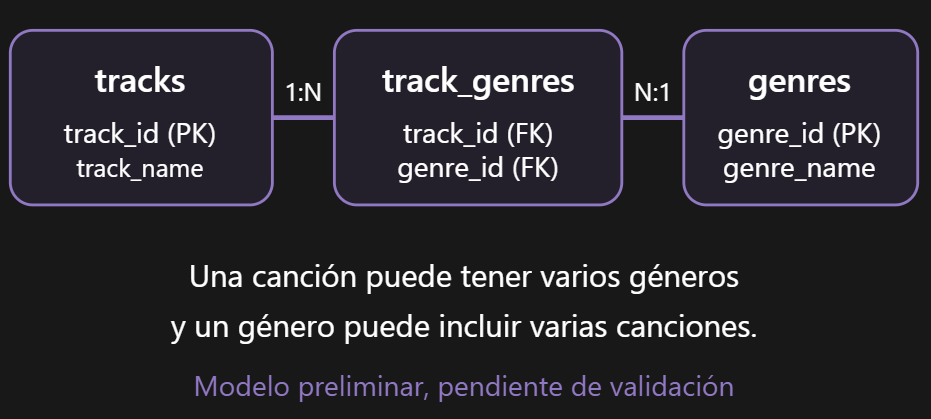


### 1.9. Análisis de canciones asociadas a múltiples géneros

Al investigar el identificador más repetido, hemos
encontrado nueve registros correspondientes a la
misma grabación:

- Artista: Badfinger
- Canción: Baby Blue - Remastered 2010
- Apariciones: 9
- Géneros distintos registrados: 9

Los registros comparten identificador, artista,
canción y álbum, pero presentan diferentes
valores en `track_genre`.

**Hallazgo:**

Una misma grabación puede estar asociada a
múltiples géneros dentro del dataset.

Esto sugiere una posible relación muchos a muchos
(N:M) entre canciones y géneros.

**Consideración sobre la calidad:**

Las etiquetas de género proceden del dataset
y no se han validado musicalmente. Algunas
asociaciones podrían ser discutibles.

**Implicación para SQL:**

Podría ser conveniente separar las canciones
y los géneros en tablas independientes, utilizando
una tabla intermedia para relacionarlos.

Este diseño es provisional y requiere comprobar
la consistencia de los registros repetidos.


In [14]:
df.loc[
    df["track_id"] == "6S3JlDAGk3uu3NtZbPnuhS",
    ["track_genre", "popularity", "duration_ms", "danceability", "energy", "tempo"]
]

,track_genre,popularity,duration_ms,danceability,energy,tempo
8315,blues,67,217346,0.623,0.876,124.431
19759,country,67,217346,0.623,0.876,124.431
34728,folk,67,217346,0.623,0.876,124.431
62226,j-pop,67,217346,0.623,0.876,124.431
63087,j-rock,67,217346,0.623,0.876,124.431
82064,power-pop,67,217346,0.623,0.876,124.431
84129,psych-rock,67,217346,0.623,0.876,124.431
99727,singer-songwriter,67,217346,0.623,0.876,124.431
102732,songwriter,67,217346,0.623,0.876,124.431



### 1.10. Comparación de características musicales

Hemos comparado los nueve registros asociados a
la canción "Baby Blue - Remastered 2010", de Badfinger.

**Resultados:**

Las nueve apariciones presentan los mismos valores en:

- Popularidad: 67
- Duración: 217.346 ms
- Danceability: 0.623
- Energy: 0.876
- Tempo: 124.431 BPM

La única diferencia observada entre las columnas
comparadas corresponde a `track_genre`.

**Conclusión provisional:**

Los resultados refuerzan la posibilidad de que
el dataset contenga múltiples clasificaciones de
género para una misma grabación.

Esto apoyaría un modelo relacional con una tabla
de canciones, una tabla de géneros y una tabla
intermedia para sus asociaciones.

Antes de confirmar este diseño, debemos comprobar
si el mismo comportamiento se mantiene en el
resto del dataset.


In [15]:
df.groupby("track_id")["energy"].nunique().gt(1).sum()

np.int64(0)


### 1.11. Consistencia de la variable `energy`

Hemos agrupado los registros por `track_id` para
comprobar si una misma canción presenta diferentes
valores de energía.

**Resultado:** 0 identificadores con valores
de energía diferentes.

Esto significa que todos los registros que
comparten un mismo `track_id` mantienen el
mismo valor de `energy`.

**Conclusión:**

La variable `energy` presenta consistencia
respecto al identificador musical.

Este resultado favorece la posibilidad de
almacenar las características acústicas una
sola vez por canción en la futura base de
datos relacional.


In [16]:
audio_features = [
    "danceability",
    "energy",
    "key",
    "loudness",
    "mode",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
    "time_signature"
]

df.groupby("track_id")[audio_features].nunique().gt(1).sum()

danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
dtype: int64


### 1.12. Consistencia de las características acústicas

Hemos analizado las 12 características acústicas
agrupando los registros por `track_id`.

**Resultado:**

Las 12 variables presentan 0 identificadores con
valores diferentes entre sus apariciones.

Las variables analizadas son:

- danceability
- energy
- key
- loudness
- mode
- speechiness
- acousticness
- instrumentalness
- liveness
- valence
- tempo
- time_signature

**Conclusión:**

Las características acústicas son consistentes
para cada identificador musical dentro del dataset.

Este resultado apoya la posibilidad de almacenar
las características musicales una sola vez por
`track_id` en una futura base de datos relacional.

Todavía debemos comprobar la consistencia de
los metadatos antes de confirmar el diseño.


In [17]:
metadata_columns = [
    "artists",
    "album_name",
    "track_name",
    "popularity",
    "duration_ms",
    "explicit"
]

df.groupby("track_id")[metadata_columns].nunique(dropna=False).gt(1).sum()

artists          0
album_name       0
track_name       0
popularity     720
duration_ms      0
explicit         0
dtype: int64


### 1.13. Consistencia de los metadatos musicales

Hemos analizado la consistencia de los metadatos
agrupando los registros por `track_id`.

**Resultados:**

- artists: 0 identificadores inconsistentes.
- album_name: 0 identificadores inconsistentes.
- track_name: 0 identificadores inconsistentes.
- popularity: 720 identificadores con valores diferentes.
- duration_ms: 0 identificadores inconsistentes.
- explicit: 0 identificadores inconsistentes.

**Hallazgo:**

La mayoría de los metadatos mantienen valores
consistentes para cada identificador musical.

Sin embargo, 720 identificadores presentan
diferentes valores de popularidad.

**Conclusión provisional:**

La popularidad requiere una investigación adicional
antes de decidir cómo representarla en la futura
base de datos SQL.

No modificaremos estos valores hasta comprender
mejor las diferencias observadas.


In [18]:
popularity_variations = (
    df.groupby("track_id")["popularity"]
    .nunique()
)

popularity_variations[popularity_variations > 1].head(10)

track_id
00YwP3wJWiG8IxAA7OS9lo    2
014SIjoLDG1Ku19c5FlDYh    2
02jLfqc9gMo8PkHEGHY3OT    2
03mHinvLdrdSTd7w4GPXwH    2
04IUJPcxiUuXih8eJIVzGz    2
04V3hO138BCddFy9TmTUic    2
04VFfRka9MBc5qlRcDuV8T    2
05UkW0aWSlpxcOlT3NtJ1N    2
05lem7bHWxyo98HOwPmils    2
05ztmc9JMq8pYE2GyY72Zd    2
Name: popularity, dtype: int64

In [19]:
df.loc[
    df["track_id"] == "00YwP3wJWiG8IxAA7OS9lo",
    [
        "artists",
        "track_name",
        "track_genre",
        "popularity"
    ]
]

,artists,track_name,track_genre,popularity
55776,Anupam Roy,Amake Amar Moto Thakte Dao,indian,47
56324,Anupam Roy,Amake Amar Moto Thakte Dao,indie-pop,47
57529,Anupam Roy,Amake Amar Moto Thakte Dao,indie,47
65813,Anupam Roy,Amake Amar Moto Thakte Dao,k-pop,47
99268,Anupam Roy,Amake Amar Moto Thakte Dao,singer-songwriter,46
102269,Anupam Roy,Amake Amar Moto Thakte Dao,songwriter,46



### 1.14. Investigación de las variaciones de popularidad

Hemos identificado 720 canciones que presentan más
de un valor de popularidad para el mismo `track_id`.

Al examinar los primeros diez identificadores
afectados, observamos que cada uno presenta
dos valores distintos de popularidad.

A continuación, analizaremos un caso concreto
para comprobar la magnitud de las diferencias
y su posible relación con las etiquetas de género.

**Objetivo:**

Determinar si las variaciones de popularidad
requieren algún tratamiento específico durante
la preparación de los datos para SQL.



### 1.15. Análisis de un caso con popularidad variable

Hemos examinado la canción "Amake Amar Moto Thakte Dao",
del artista Anupam Roy.

**Resultados:**

- Registros encontrados: 6
- Géneros registrados: 6
- Valores de popularidad: 46 y 47
- Diferencia entre valores: 1 punto

Los registros comparten el mismo identificador musical,
pero presentan diferentes etiquetas de género y
dos valores de popularidad.

**Interpretación:**

La diferencia observada es pequeña, pero confirma
que `popularity` no es completamente consistente
para todos los registros de un mismo `track_id`.

No disponemos de información suficiente para
determinar el origen de esta variación.

**Implicaciones para SQL:**

Antes de crear una tabla de canciones con una
única popularidad por `track_id`, será necesario
establecer y documentar un criterio de tratamiento.

No realizaremos modificaciones durante esta
fase exploratoria.


In [20]:
popularity_range = df.groupby("track_id")["popularity"].agg(
    ["min", "max"]
)

popularity_range["difference"] = (
    popularity_range["max"] - popularity_range["min"]
)

popularity_range[
    popularity_range["difference"] > 0
].sort_values("difference", ascending=False).head(10)

,min,max,difference
track_id,,,
5hljqZrl0h7RcIhUnOPuve,0,44,44
1UwUhKmFxGKs59xiWO60Sx,0,42,42
0C6dSPCqwKqwos6s1CrDrh,0,42,42
5ygEUpyZy5qtZ1423zymBW,0,41,41
1zx6GSqLYI2ynzAHnPRKBR,0,41,41
4KPi4VNvPOfKqIp1sx19Xf,0,41,41
5fClRRa7P9nPIpstj50veV,0,40,40
0z5x3VmmQ7cyTeOP7VAf3T,0,40,40
42GuKw49pPxNAkIhWGwgFs,0,39,39



### 1.16. Magnitud de las diferencias de popularidad

Hemos calculado la diferencia entre los valores
máximos y mínimos de popularidad para cada `track_id`.

**Resultados:**

- Se habían identificado 720 canciones con
  diferentes valores de popularidad.
- La mayor diferencia encontrada es de 44 puntos.
- Los diez casos con mayores diferencias presentan
  un valor mínimo de popularidad igual a 0.

**Hallazgo:**

Las variaciones de popularidad no son siempre
pequeñas. Algunas canciones presentan diferencias
considerables entre sus registros.

**Interpretación:**

No podemos determinar todavía si los valores
iguales a 0 representan datos válidos o posibles
problemas en la recopilación de información.

**Conclusión provisional:**

La variable `popularity` requiere una revisión
específica antes de utilizarse en análisis SQL.

No se aplicarán transformaciones hasta investigar
los casos extremos.


In [21]:
df.loc[
    df["track_id"] == "5hljqZrl0h7RcIhUnOPuve",
    [
        "artists",
        "track_name",
        "track_genre",
        "popularity",
        "duration_ms"
    ]
]

,artists,track_name,track_genre,popularity,duration_ms
38030,Arctic Monkeys,Sculptures Of Anything Goes,garage,0,239151
57792,Arctic Monkeys,Sculptures Of Anything Goes,indie,0,239151
91956,Arctic Monkeys,Sculptures Of Anything Goes,rock,44,239151



### 1.17. Estudio de un caso extremo: Arctic Monkeys

Hemos investigado la canción "Sculptures Of Anything Goes",
del grupo Arctic Monkeys.

**Resultados:**

- Registros encontrados: 3
- Géneros: garage, indie y rock
- Popularidad registrada: 0, 0 y 44
- Diferencia máxima: 44 puntos
- Duración: 239151 ms en los tres registros

**Hallazgo:**

Una misma canción presenta valores de popularidad
muy diferentes, aunque su identificador y duración
son consistentes.

**Interpretación:**

No disponemos de información suficiente para
determinar el origen de esta discrepancia.

Calcular una media directamente podría introducir
un valor poco representativo, especialmente porque
las canciones aparecen un número variable de veces
según sus etiquetas de género.

**Conclusión provisional:**

Será necesario definir un criterio de tratamiento
para la popularidad antes de crear la base de datos SQL.


In [22]:
(df["popularity"] == 0).sum()

np.int64(16020)


### 1.18. Registros con popularidad igual a cero

Hemos contado los registros donde `popularity` es 0.

**Resultados:**

- Total de registros: 114000
- Registros con popularidad 0: 16020
- Porcentaje: 14,05 %

**Interpretación:**

Una proporción relevante del dataset presenta
popularidad igual a cero.

Este resultado corresponde a filas, no a canciones
únicas, ya que un mismo `track_id` puede aparecer
en varios registros.

No podemos considerar estos ceros como errores
sin realizar comprobaciones adicionales.


In [23]:
popularity_by_track = df.groupby("track_id")["popularity"].agg(
    ["min", "max"]
)

(
    (popularity_by_track["min"] == 0)
    & (popularity_by_track["max"] > 0)
).sum()

np.int64(105)


### 1.19. Canciones con popularidad cero y positiva

Hemos agrupado los registros por `track_id` para
identificar canciones con valores de popularidad
iguales a cero y superiores a cero.

**Resultados:**

- Canciones con popularidad variable: 720
- Canciones con valores cero y positivos: 105
- Canciones con diferentes valores positivos: 615

**Interpretación:**

Las inconsistencias de popularidad presentan
dos situaciones diferentes:

1. Canciones con valores cero y positivos.
2. Canciones con varios valores positivos.

Por tanto, las diferencias no se explican
únicamente por la presencia de ceros.

**Conclusión provisional:**

La popularidad necesita un criterio de tratamiento
documentado antes de consolidar los registros
en la futura base de datos relacional.

Todavía no podemos determinar si los valores cero
son correctos o reflejan problemas de recopilación.


In [24]:
(popularity_by_track["max"] == 0).sum()

np.int64(9348)


### 1.20. Canciones con popularidad exclusivamente cero

Hemos agrupado los registros por `track_id`
para identificar canciones cuya popularidad
máxima es igual a cero.

**Resultado:**

- Canciones con popularidad siempre igual a 0: 9348
- Porcentaje sobre identificadores únicos: 10,42 %

**Resumen de los hallazgos:**

- 9348 canciones tienen únicamente popularidad cero.
- 105 canciones presentan valores cero y positivos.
- 615 canciones presentan diferentes valores positivos.

**Interpretación:**

La mayoría de las canciones con popularidad cero
no presentan valores contradictorios dentro del dataset.

Sin embargo, no podemos confirmar que esos ceros
representen correctamente su popularidad real.

**Conclusión provisional:**

No eliminaremos los valores cero automáticamente.

La variable `popularity` requerirá criterios
específicos de tratamiento durante la limpieza.


In [25]:
df["popularity"].describe()

count    114000.000000
mean         33.238535
std          22.305078
min           0.000000
25%          17.000000
50%          35.000000
75%          50.000000
max         100.000000
Name: popularity, dtype: float64


### 1.21. Estadísticas descriptivas de popularidad

Hemos utilizado `describe()` para estudiar la
distribución general de la variable `popularity`.

**Resultados:**

- Registros analizados: 114000
- Media: 33,24
- Mediana: 35
- Desviación estándar: 22,31
- Mínimo: 0
- Primer cuartil: 17
- Tercer cuartil: 50
- Máximo: 100

**Interpretación:**

La mitad central de los registros presenta valores
de popularidad comprendidos entre 17 y 50.

La media y la mediana son relativamente próximas,
aunque existe una dispersión considerable.

**Limitación:**

Estas estadísticas se calculan sobre registros,
no sobre canciones únicas.

Las canciones asociadas a varios géneros pueden
tener mayor peso en los resultados.

**Conclusión provisional:**

Será necesario resolver las duplicaciones por
`track_id` antes de calcular estadísticas
representativas de canciones únicas.


In [28]:
%pip install matplotlib

   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ------- -------------------------------- 1.8/9.5 MB 9.0 MB/s eta 0:00:01
   ---------------------------------------  9.4/9.5 MB 25.1 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 22.8 MB/s  0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 38.2 MB/s  0:00:00
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   ---------------------------------------- 7.3/7.3 MB 39.9 MB/s  0:00:00

   ---------------------------------------- 0/7 [pyparsing]
   ---------------------------------------- 0/7 [pyparsing]
   ---------------------------------------- 0/7 [pyparsing]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- 

In [29]:
import matplotlib.pyplot as plt

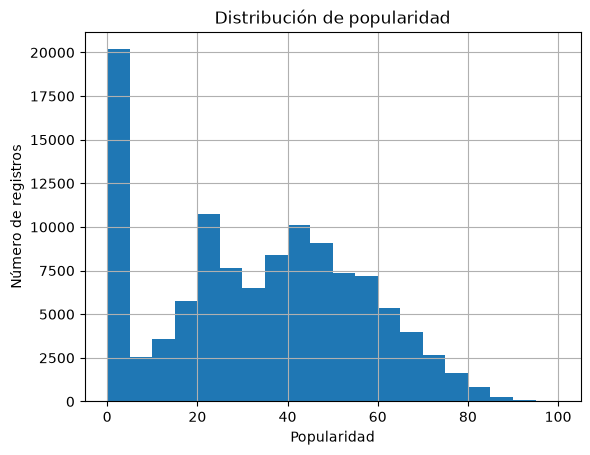

In [30]:
df["popularity"].hist(bins=20)

plt.title("Distribución de popularidad")
plt.xlabel("Popularidad")
plt.ylabel("Número de registros")
plt.show()


### 1.22. Visualización de la distribución de popularidad

Hemos representado la variable `popularity`
mediante un histograma de 20 intervalos.

**Observaciones:**

- Existe un pico muy pronunciado en el intervalo
  de popularidad más bajo.
- Se observa una concentración importante de
  registros entre 20 y 60 puntos.
- La frecuencia disminuye progresivamente en
  los valores de popularidad más elevados.
- Los registros próximos a 100 son poco frecuentes.

**Interpretación:**

La distribución no es uniforme y presenta una
concentración destacada de valores bajos,
especialmente alrededor de cero.

Este comportamiento debe interpretarse teniendo
en cuenta las inconsistencias detectadas
previamente en la variable `popularity`.

**Limitaciones:**

El histograma representa los 114000 registros
originales, no las canciones únicas.

Una misma canción puede contribuir varias veces
a la distribución si aparece en distintos géneros.

**Conclusión provisional:**

La popularidad puede ser una variable interesante
para futuros análisis, pero requiere un tratamiento
documentado antes de utilizarse en comparaciones
entre canciones o géneros.
